# Proyek Analisis Data: [Bike Sharing Dataset]
- **Nama:** [Ashyfa Rosalia Putri. A]
- **Email:** [rosaworkspace9@gmail.com]
- **ID Dicoding:** [ds429b6x0272]

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

Dataset yang digunakan adalah **Bike Sharing Dataset** (Capital Bikeshare, Washington D.C., 2011-2012) yang terdiri dari `day.csv` (agregasi harian, 731 baris) dan `hour.csv` (agregasi per jam, 17.379 baris). Pertanyaan bisnis berikut disusun dengan metode SMART.

- **Pertanyaan 1:** Pada jam berapa jumlah penyewaan sepeda mencapai puncak pada hari kerja dibandingkan akhir pekan/hari libur sepanjang tahun 2012, dan berapa persentase pengguna *casual* dibandingkan *registered* pada masing-masing kelompok hari tersebut?
- **Pertanyaan 2:** Bagaimana pengaruh musim dan kondisi cuaca terhadap rata-rata jumlah penyewaan sepeda harian pada tahun 2011 dibandingkan 2012, dan kondisi cuaca mana yang menurunkan penyewaan paling besar dibandingkan hari cerah?

**Mengapa memenuhi SMART?**
- *Specific*: fokus pada pola jam (Q1) serta musim dan cuaca (Q2), bukan sekadar "penyewaan naik/turun".
- *Measurable*: diukur dengan rata-rata penyewaan per jam, persentase pengguna casual/registered, rata-rata penyewaan harian, dan persentase penurunan.
- *Action-Oriented*: hasilnya dipakai untuk menentukan alokasi stok sepeda per jam, target promosi, dan strategi saat cuaca buruk.
- *Relevant*: ketersediaan sepeda pada jam sibuk dan sensitivitas terhadap cuaca adalah masalah operasional utama layanan bike sharing.
- *Time-bound*: Q1 dibatasi pada tahun 2012, Q2 membandingkan 2011 vs 2012.


## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

## Data Wrangling

### Gathering Data

#### Load day_df dan hour_df

In [2]:
import os
import zipfile
import gdown

# URL dari Google Drive yang Anda berikan
grive_url = "https://drive.google.com/file/d/1RaBmV6Q6FYWU4HWZs80Suqd7KQC34diQ/view"

# Mengekstrak ID file dari URL Google Drive
file_id = "1RaBmV6Q6FYWU4HWZs80Suqd7KQC34diQ"
download_url = f"https://drive.google.com/uc?export=download&id={file_id}"

# Output path untuk file zip
zip_output = "bike_sharing_dataset.zip"

# Unduh file jika belum ada
if not os.path.exists(zip_output):
    print("Mengunduh dataset dari Google Drive...")
    gdown.download(download_url, zip_output, quiet=False)

# Ekstrak file zip ke dalam folder 'data'
if not os.path.exists("data"):
    print("Mengekstrak file...")
    with zipfile.ZipFile(zip_output, 'r') as zip_ref:
        zip_ref.extractall("data")

# Membaca dataset setelah diekstrak
day_df = pd.read_csv("data/day.csv")
hour_df = pd.read_csv("data/hour.csv")

print("Ukuran day_df :", day_df.shape)
print("Ukuran hour_df:", hour_df.shape)
day_df.head()

Mengunduh dataset dari Google Drive...


Downloading...
From: https://drive.google.com/uc?export=download&id=1RaBmV6Q6FYWU4HWZs80Suqd7KQC34diQ
To: /content/bike_sharing_dataset.zip
100%|██████████| 280k/280k [00:00<00:00, 91.1MB/s]

Mengekstrak file...
Ukuran day_df : (731, 16)
Ukuran hour_df: (17379, 17)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [3]:
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**
- `day_df` berisi 731 baris (1 Januari 2011 sampai 31 Desember 2012) dan `hour_df` berisi 17.379 baris dengan tambahan kolom `hr` (jam).
- Kolom `season`, `weathersit`, `yr`, `mnth`, `weekday`, dan `workingday` masih berupa kode angka, dan `temp`, `atemp`, `hum`, `windspeed` masih dalam bentuk ternormalisasi. Keduanya perlu diperbaiki agar mudah dibaca.


### Assessing Data

#### Memeriksa tipe data, missing value, dan duplikasi


In [4]:
day_df.info()
print()
hour_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (to

In [5]:
print("Missing value day_df :", day_df.isna().sum().sum())
print("Missing value hour_df:", hour_df.isna().sum().sum())
print("Duplikat day_df :", day_df.duplicated().sum())
print("Duplikat hour_df:", hour_df.duplicated().sum())

Missing value day_df : 0
Missing value hour_df: 0
Duplikat day_df : 0
Duplikat hour_df: 0


In [6]:
# 1. Kelembapan (hum) bernilai 0 tidak masuk akal untuk kondisi cuaca di Washington D.C.
print("Baris hum == 0 di day_df :", (day_df["hum"] == 0).sum())
print(day_df.loc[day_df["hum"] == 0, ["dteday", "hum", "weathersit", "cnt"]])
print("Baris hum == 0 di hour_df:", (hour_df["hum"] == 0).sum())

# 2. Konsistensi antara data harian dan data per jam
cnt_per_hari = hour_df.groupby("dteday")["cnt"].sum()
selisih = (cnt_per_hari.reindex(day_df["dteday"]).values != day_df["cnt"].values).sum()
print("\nJumlah hari yang total cnt per jamnya tidak sama dengan day_df:", selisih)
print("casual + registered == cnt (day_df) :", (day_df["casual"] + day_df["registered"] == day_df["cnt"]).all())
print("casual + registered == cnt (hour_df):", (hour_df["casual"] + hour_df["registered"] == hour_df["cnt"]).all())

Baris hum == 0 di day_df : 1
        dteday  hum  weathersit  cnt
68  2011-03-10  0.0           3  623
Baris hum == 0 di hour_df: 22

Jumlah hari yang total cnt per jamnya tidak sama dengan day_df: 0
casual + registered == cnt (day_df) : True
casual + registered == cnt (hour_df): True


#### Memeriksa kelengkapan data per jam dan inconsistent value


In [7]:
total_diharapkan = len(day_df) * 24
print("Jumlah baris hour_df :", len(hour_df))
print("Jumlah seharusnya    :", total_diharapkan)
print("Jam yang tidak tercatat:", total_diharapkan - len(hour_df))
print("Jumlah hari dengan catatan kurang dari 24 jam:", (hour_df.groupby("dteday").size() < 24).sum())

print("\nTipe data kolom dteday:", day_df["dteday"].dtype)
print("\nDistribusi weathersit di day_df:")
print(day_df["weathersit"].value_counts().sort_index())

Jumlah baris hour_df : 17379
Jumlah seharusnya    : 17544
Jam yang tidak tercatat: 165
Jumlah hari dengan catatan kurang dari 24 jam: 76

Tipe data kolom dteday: object

Distribusi weathersit di day_df:
weathersit
1    463
2    247
3     21
Name: count, dtype: int64


#### Memeriksa outlier (metode IQR)


In [8]:
def hitung_outlier(df, kolom):
    q1, q3 = df[kolom].quantile([0.25, 0.75])
    iqr = q3 - q1
    batas_bawah, batas_atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((df[kolom] < batas_bawah) | (df[kolom] > batas_atas)).sum()

for kolom in ["casual", "registered", "cnt", "hum", "windspeed"]:
    print(f"Outlier pada {kolom:<10}: {hitung_outlier(day_df, kolom)} dari {len(day_df)} baris")

Outlier pada casual    : 44 dari 731 baris
Outlier pada registered: 0 dari 731 baris
Outlier pada cnt       : 0 dari 731 baris
Outlier pada hum       : 2 dari 731 baris
Outlier pada windspeed : 13 dari 731 baris


**Steps to Take:**
- Kolom `dteday` bertipe string (*inconsistent value*), jadi perlu diubah ke `datetime`.
- Kolom kategori (`season`, `yr`, `mnth`, `weekday`, `workingday`, `weathersit`) berisi kode angka (*inaccurate/uninformative value*), jadi perlu diberi label yang bermakna. Kolom `temp`, `atemp`, `hum`, dan `windspeed` perlu dikembalikan ke satuan aslinya.
- Kelembapan `hum` bernilai 0 (*invalid value*) perlu diganti dengan nilai median kelembapan pada bulan dan tahun yang sama.
- Data per jam tidak lengkap (*incomplete data*) karena jam tanpa transaksi tidak dicatat. Baris tidak ditambahkan, tetapi keterbatasan ini dicatat saat menafsirkan rata-rata per jam.
- Outlier pada `casual` dan `windspeed` adalah variasi alami (hari libur atau cuaca ekstrem), sehingga **dipertahankan** agar pola permintaan tidak terdistorsi.

**Insight:**
- Tidak ada *missing value* maupun data duplikat pada kedua dataset.
- Total `cnt` per jam konsisten dengan total harian di `day_df`, dan `casual + registered = cnt` terpenuhi, sehingga kedua file dapat dipakai bersama.
- Ditemukan 1 baris `hum = 0` pada `day_df` (22 baris pada `hour_df`) serta 165 jam yang tidak tercatat pada `hour_df`.
- Kategori cuaca 4 (hujan/salju lebat) tidak muncul pada data harian.

### Cleaning Data

#### Mengubah tipe data dan mengganti nilai kelembapan yang tidak valid


In [9]:
# 1. Ubah dteday menjadi datetime
for df in (day_df, hour_df):
    df["dteday"] = pd.to_datetime(df["dteday"])

# 2. Ganti hum == 0 dengan median hum pada bulan dan tahun yang sama
day_df.loc[day_df["hum"] == 0, "hum"] = np.nan
day_df["hum"] = day_df.groupby(["yr", "mnth"])["hum"].transform(lambda x: x.fillna(x.median()))

# pada hour_df, gunakan nilai kelembapan harian yang sudah dibersihkan
hum_harian = day_df.set_index("dteday")["hum"]
mask = hour_df["hum"] == 0
hour_df.loc[mask, "hum"] = hour_df.loc[mask, "dteday"].map(hum_harian)

print("hum == 0 tersisa (day_df) :", (day_df["hum"] == 0).sum())
print("hum == 0 tersisa (hour_df):", (hour_df["hum"] == 0).sum())
print("dtype dteday:", day_df["dteday"].dtype)

hum == 0 tersisa (day_df) : 0
hum == 0 tersisa (hour_df): 0
dtype dteday: datetime64[ns]


#### Memberi label pada kolom kategori dan mengembalikan satuan asli

In [10]:
season_map = {1: "Spring", 2: "Summer", 3: "Fall", 4: "Winter"}
weather_map = {1: "Cerah", 2: "Berkabut/Mendung", 3: "Hujan/Salju Ringan", 4: "Hujan/Salju Lebat"}
weekday_map = {0: "Minggu", 1: "Senin", 2: "Selasa", 3: "Rabu", 4: "Kamis", 5: "Jumat", 6: "Sabtu"}
month_map = {1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "Mei", 6: "Jun",
             7: "Jul", 8: "Agu", 9: "Sep", 10: "Okt", 11: "Nov", 12: "Des"}

def beri_label(df):
    df = df.copy()
    df["season"] = pd.Categorical(df["season"].map(season_map), categories=list(season_map.values()), ordered=True)
    df["weathersit"] = pd.Categorical(df["weathersit"].map(weather_map), categories=list(weather_map.values()), ordered=True)
    df["weekday"] = df["weekday"].map(weekday_map)
    df["mnth"] = df["mnth"].map(month_map)
    df["yr"] = df["yr"].map({0: 2011, 1: 2012})
    df["workingday"] = df["workingday"].map({0: "Akhir Pekan/Libur", 1: "Hari Kerja"})
    # kembalikan ke satuan asli (sesuai Readme dataset)
    df["temp_c"] = df["temp"] * 41
    df["atemp_c"] = df["atemp"] * 50
    df["hum_pct"] = df["hum"] * 100
    df["windspeed_kmh"] = df["windspeed"] * 67
    return df.drop(columns=["instant", "temp", "atemp", "hum", "windspeed"])

day_df = beri_label(day_df)
hour_df = beri_label(hour_df)
day_df.head()

,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,casual,registered,cnt,temp_c,atemp_c,hum_pct,windspeed_kmh
0,2011-01-01,Spring,2011,Jan,0,Sabtu,Akhir Pekan/Libur,Berkabut/Mendung,331,654,985,14.110847,18.18125,80.5833,10.749882
1,2011-01-02,Spring,2011,Jan,0,Minggu,Akhir Pekan/Libur,Berkabut/Mendung,131,670,801,14.902598,17.68695,69.6087,16.652113
2,2011-01-03,Spring,2011,Jan,0,Senin,Hari Kerja,Cerah,120,1229,1349,8.050924,9.47025,43.7273,16.636703
3,2011-01-04,Spring,2011,Jan,0,Selasa,Hari Kerja,Cerah,108,1454,1562,8.200000,10.60610,59.0435,10.739832
4,2011-01-05,Spring,2011,Jan,0,Rabu,Hari Kerja,Cerah,82,1518,1600,9.305237,11.46350,43.6957,12.522300


**Insight:**
- Setelah cleaning, kolom `dteday` bertipe `datetime`, kolom kategori sudah berlabel, dan nilai kelembapan 0 sudah diganti.
- Kolom `instant` dihapus karena hanya berupa nomor urut. Kolom suhu, kelembapan, dan kecepatan angin kini memakai satuan asli (°C, %, km/jam).


## Exploratory Data Analysis (EDA)

Explore statistik deskriptif

In [11]:
day_df[['casual', 'registered', 'cnt', 'temp_c', 'hum_pct', 'windspeed_kmh']].describe().round(2)

,casual,registered,cnt,temp_c,hum_pct,windspeed_kmh
count,731.00,731.00,731.00,731.00,731.00,731.00
mean,848.18,3656.17,4504.35,20.31,62.87,12.76
std,686.62,1560.26,1937.21,7.51,14.05,5.19
min,2.00,20.00,22.00,2.42,18.79,1.50
25%,315.50,2497.00,3152.00,13.82,52.10,9.04
50%,713.00,3662.00,4548.00,20.43,62.67,12.13
75%,1096.00,4776.50,5956.00,26.87,73.02,15.63
max,3410.00,6946.00,8714.00,35.33,97.25,34.00


### Explore pola penyewaan per jam (2012): hari kerja vs akhir pekan/libur

In [12]:
hour_2012 = hour_df[hour_df["yr"] == 2012]

pola_jam = (hour_2012.groupby(["workingday", "hr"], observed=True)["cnt"].mean()
            .unstack(0).round(1))
print("Top 3 jam tersibuk, Hari Kerja:")
print(pola_jam["Hari Kerja"].nlargest(3))
print("\nTop 3 jam tersibuk, Akhir Pekan/Libur:")
print(pola_jam["Akhir Pekan/Libur"].nlargest(3))

Top 3 jam tersibuk, Hari Kerja:
hr
17    656.2
18    617.0
8     604.5
Name: Hari Kerja, dtype: float64

Top 3 jam tersibuk, Akhir Pekan/Libur:
hr
13    458.9
12    451.0
14    447.9
Name: Akhir Pekan/Libur, dtype: float64


In [13]:
komposisi = hour_2012.groupby("workingday")[["casual", "registered"]].sum()
komposisi["total"] = komposisi.sum(axis=1)
komposisi["pct_casual"] = (komposisi["casual"] / komposisi["total"] * 100).round(1)
komposisi["pct_registered"] = (komposisi["registered"] / komposisi["total"] * 100).round(1)
komposisi

,casual,registered,total,pct_casual,pct_registered
workingday,,,,,
Akhir Pekan/Libur,187834,425596,613430,30.6,69.4
Hari Kerja,184931,1251215,1436146,12.9,87.1


### Explore pengaruh musim dan cuaca terhadap penyewaan harian

In [14]:
rata_musim = day_df.groupby(["yr", "season"], observed=True)["cnt"].mean().unstack(0).round(0)
rata_cuaca = day_df.groupby(["yr", "weathersit"], observed=True)["cnt"].mean().unstack(0).round(0)
print("Rata-rata penyewaan harian per musim:")
print(rata_musim)
print("\nRata-rata penyewaan harian per kondisi cuaca:")
print(rata_cuaca)
print("\nJumlah hari per kondisi cuaca:")
print(day_df.groupby(["yr", "weathersit"], observed=True).size().unstack(0))

Rata-rata penyewaan harian per musim:
yr        2011    2012
season                
Spring  1667.0  3531.0
Summer  3775.0  6209.0
Fall    4464.0  6824.0
Winter  3664.0  5792.0

Rata-rata penyewaan harian per kondisi cuaca:
yr                    2011    2012
weathersit                        
Cerah               3695.0  6004.0
Berkabut/Mendung    3088.0  4991.0
Hujan/Salju Ringan  1674.0  2126.0

Jumlah hari per kondisi cuaca:
yr                  2011  2012
weathersit                    
Cerah                226   237
Berkabut/Mendung     124   123
Hujan/Salju Ringan    15     6


In [15]:
# Persentase perbedaan tiap kondisi cuaca dibandingkan hari cerah
selisih_cuaca = ((rata_cuaca / rata_cuaca.loc["Cerah"] - 1) * 100).round(1)
selisih_cuaca

yr,2011,2012
weathersit,,
Cerah,0.0,0.0
Berkabut/Mendung,-16.4,-16.9
Hujan/Salju Ringan,-54.7,-64.6


**Insight:**
- Pada 2012, puncak penyewaan hari kerja terjadi pukul **17:00** (rata-rata 656 sepeda/jam) dengan puncak kedua pukul 08:00. Pola dua puncak ini sesuai jam berangkat dan pulang kerja.
- Pada akhir pekan/libur, puncaknya pukul **13:00** (rata-rata 459 sepeda/jam) dan permintaan tinggi sepanjang siang.
- Pengguna *casual* menyumbang 30.6% penyewaan pada akhir pekan/libur, sedangkan pada hari kerja hanya 12.9%.
- Rata-rata penyewaan harian naik dari 3,406 (2011) menjadi 5,600 (2012), atau 64.4%.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Jam puncak penyewaan (hari kerja vs akhir pekan/libur, 2012) dan komposisi pengguna

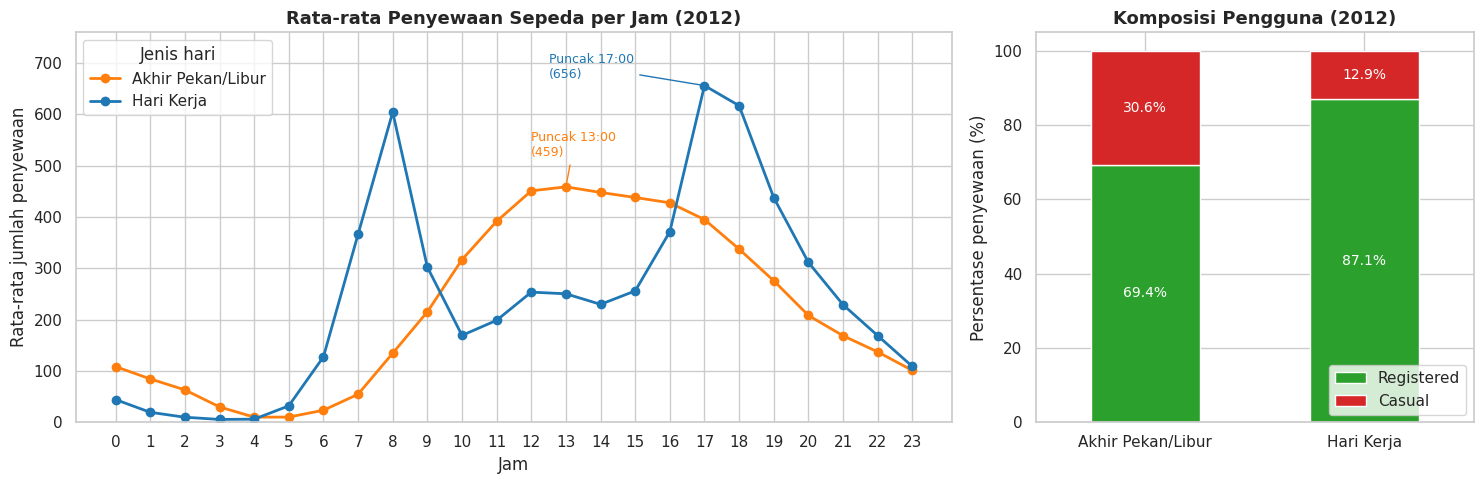

In [16]:
warna = {"Hari Kerja": "#1f77b4", "Akhir Pekan/Libur": "#ff7f0e"}
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [2, 1]})

# (a) Pola rata-rata penyewaan per jam
for kelompok in pola_jam.columns:
    axes[0].plot(pola_jam.index, pola_jam[kelompok], marker="o", linewidth=2, label=kelompok, color=warna[kelompok])
    jam_puncak = pola_jam[kelompok].idxmax()
    axes[0].annotate(f"Puncak {jam_puncak}:00\n({pola_jam[kelompok].max():.0f})",
                     xy=(jam_puncak, pola_jam[kelompok].max()),
                     xytext=(jam_puncak - 4.5 if kelompok == "Hari Kerja" else jam_puncak - 1, pola_jam[kelompok].max() + (15 if kelompok == "Hari Kerja" else 60)),
                     fontsize=9, color=warna[kelompok],
                     arrowprops=dict(arrowstyle="-", color=warna[kelompok], lw=1))
axes[0].set_title("Rata-rata Penyewaan Sepeda per Jam (2012)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Jam")
axes[0].set_ylabel("Rata-rata jumlah penyewaan")
axes[0].set_xticks(range(0, 24))
axes[0].set_ylim(0, 760)
axes[0].legend(title="Jenis hari", loc="upper left")

# (b) Komposisi pengguna
komposisi[["pct_registered", "pct_casual"]].plot(kind="bar", stacked=True, ax=axes[1],
                                                 color=["#2ca02c", "#d62728"], rot=0)
axes[1].set_title("Komposisi Pengguna (2012)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("")
axes[1].set_ylabel("Persentase penyewaan (%)")
axes[1].legend(["Registered", "Casual"], loc="lower right")
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.1f%%", label_type="center", color="white", fontsize=10)

plt.tight_layout()
plt.show()

### Pertanyaan 2: Pengaruh musim dan cuaca terhadap rata-rata penyewaan harian (2011 vs 2012)

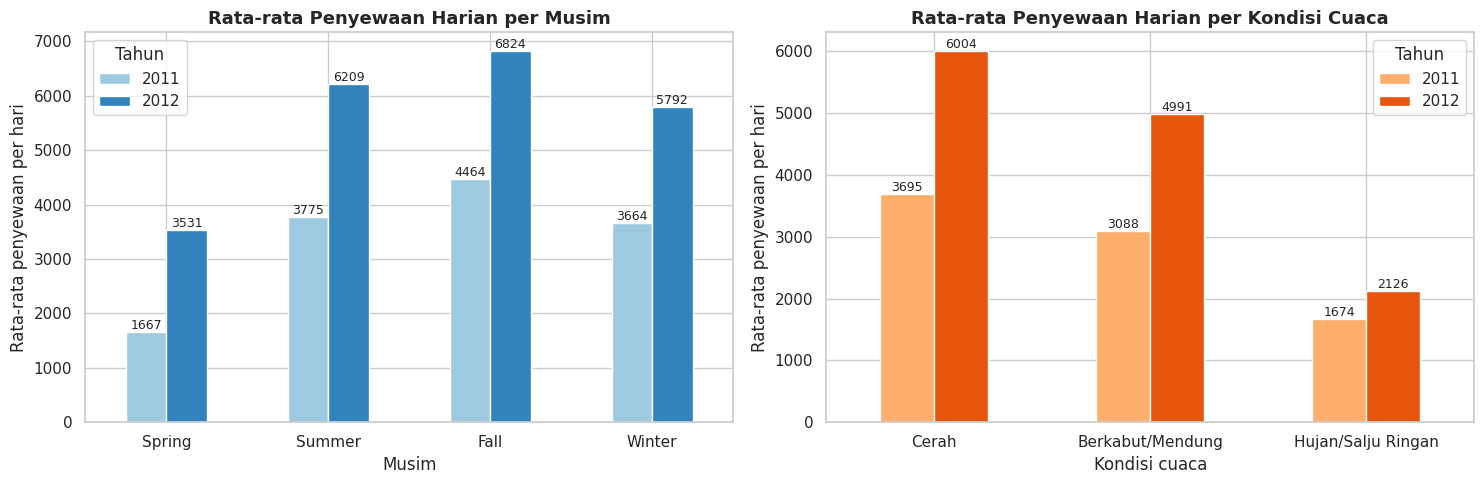

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# (a) Musim
rata_musim.plot(kind="bar", ax=axes[0], color=["#9ecae1", "#3182bd"], rot=0)
axes[0].set_title("Rata-rata Penyewaan Harian per Musim", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Musim")
axes[0].set_ylabel("Rata-rata penyewaan per hari")
axes[0].legend(title="Tahun")
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.0f", fontsize=9)

# (b) Cuaca
rata_cuaca.plot(kind="bar", ax=axes[1], color=["#fdae6b", "#e6550d"], rot=0)
axes[1].set_title("Rata-rata Penyewaan Harian per Kondisi Cuaca", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Kondisi cuaca")
axes[1].set_ylabel("Rata-rata penyewaan per hari")
axes[1].legend(title="Tahun")
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.0f", fontsize=9)

plt.tight_layout()
plt.show()

**Insight Pertanyaan 1:**
- Hari kerja memiliki dua puncak tajam (pukul 08:00 dan 17:00), sedangkan akhir pekan/libur memiliki satu puncak landai di sekitar pukul 13:00.
- Pengguna *casual* berkontribusi 30.6% pada akhir pekan/libur, jauh lebih besar daripada hari kerja (12.9%). Pola ini mengindikasikan penggunaan rekreasi pada akhir pekan/libur dan penggunaan komuter oleh pelanggan terdaftar pada hari kerja.

**Insight Pertanyaan 2:**
- Penyewaan tertinggi terjadi pada musim **Fall** (4,464 per hari pada 2011 dan 6,824 pada 2012), dan terendah pada **Spring** (1,667 dan 3,531).
- Cuaca buruk menurunkan penyewaan. Dibandingkan hari cerah, hujan/salju ringan turun **54.7%** pada 2011 dan **64.6%** pada 2012, dan hari berkabut/mendung turun 16.4% dan 16.9%.
- Semua kondisi naik pada 2012, tetapi hari hujan/salju ringan naik paling kecil dan masih jauh di bawah hari cerah.
- Perhatian: hari hujan/salju ringan hanya 15 hari pada 2011 dan 6 hari pada 2012, sehingga angkanya perlu ditafsirkan dengan hati-hati.

## Analisis Lanjutan (Opsional)

In [18]:
# 1. Binning jam menjadi kategori waktu
bins_waktu = [-1, 5, 11, 15, 20, 23]
label_waktu = ["Dini Hari (00-05)", "Pagi (06-11)", "Siang (12-15)", "Sore (16-20)", "Malam (21-23)"]
hour_df["kategori_waktu"] = pd.cut(hour_df["hr"], bins=bins_waktu, labels=label_waktu)

# 2. Binning suhu (derajat Celsius)
bins_suhu = [0, 15, 25, 40]
label_suhu = ["Dingin (<15°C)", "Sejuk (15-25°C)", "Panas (>25°C)"]
day_df["kategori_suhu"] = pd.cut(day_df["temp_c"], bins=bins_suhu, labels=label_suhu)

# 3. Manual grouping tingkat permintaan harian
day_df["tingkat_permintaan"] = pd.cut(day_df["cnt"], bins=[0, 3000, 6000, np.inf],
                                      labels=["Rendah (<3.000)", "Sedang (3.000-6.000)", "Tinggi (>6.000)"])

waktu_2012 = (hour_df[hour_df["yr"] == 2012]
              .groupby(["kategori_waktu", "workingday"], observed=True)["cnt"].mean().unstack().round(1))
suhu_cnt = day_df.groupby("kategori_suhu", observed=True)["cnt"].mean().round(0)
permintaan_cuaca = pd.crosstab(day_df["weathersit"], day_df["tingkat_permintaan"], normalize="index").mul(100).round(1)

print("Rata-rata penyewaan per jam menurut kategori waktu (2012):")
print(waktu_2012)
print("\nRata-rata penyewaan harian menurut kategori suhu:")
print(suhu_cnt)
print("\nPersentase hari menurut tingkat permintaan pada tiap kondisi cuaca (%):")
print(permintaan_cuaca)

Rata-rata penyewaan per jam menurut kategori waktu (2012):
workingday         Akhir Pekan/Libur  Hari Kerja
kategori_waktu                                  
Dini Hari (00-05)               51.1        19.6
Pagi (06-11)                   189.4       294.8
Siang (12-15)                  449.0       247.4
Sore (16-20)                   328.9       478.8
Malam (21-23)                  135.6       168.9

Rata-rata penyewaan harian menurut kategori suhu:
kategori_suhu
Dingin (<15°C)     2833.0
Sejuk (15-25°C)    4864.0
Panas (>25°C)      5632.0
Name: cnt, dtype: float64

Persentase hari menurut tingkat permintaan pada tiap kondisi cuaca (%):
tingkat_permintaan  Rendah (<3.000)  Sedang (3.000-6.000)  Tinggi (>6.000)
weathersit                                                                
Cerah                          16.8                  52.9             30.2
Berkabut/Mendung               30.4                  53.4             16.2
Hujan/Salju Ringan             90.5                   9.

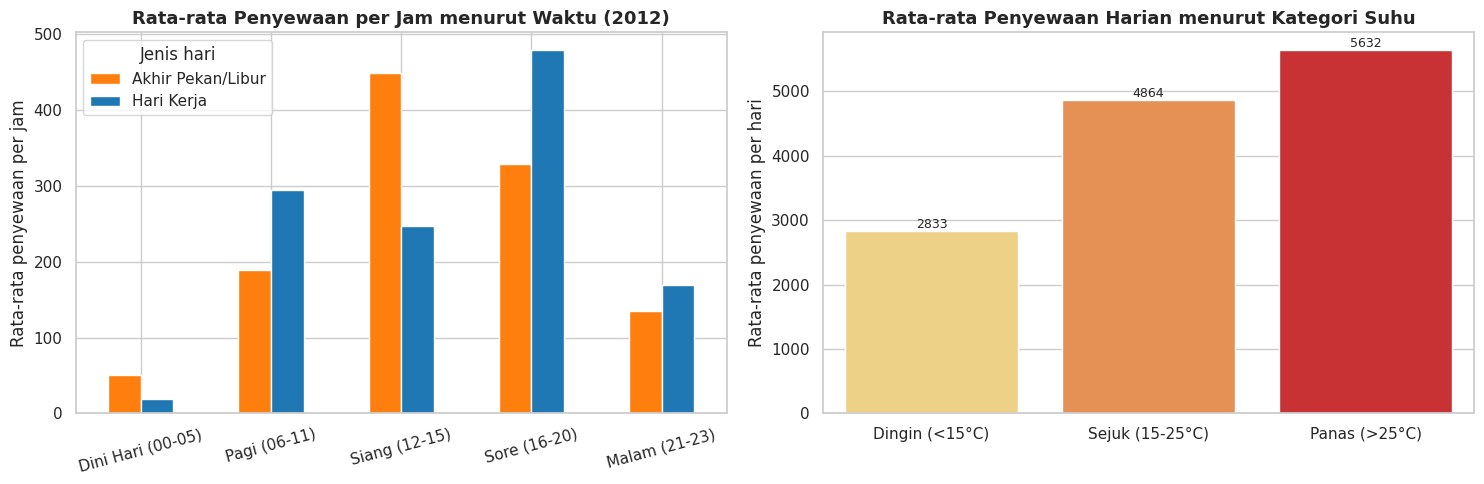

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

waktu_2012.plot(kind="bar", ax=axes[0], color=["#1f77b4", "#ff7f0e"][::-1], rot=15)
axes[0].set_title("Rata-rata Penyewaan per Jam menurut Waktu (2012)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("")
axes[0].set_ylabel("Rata-rata penyewaan per jam")
axes[0].legend(title="Jenis hari")

sns.barplot(x=suhu_cnt.index, y=suhu_cnt.values, ax=axes[1], hue=suhu_cnt.index, palette="YlOrRd", legend=False, dodge=False)
axes[1].set_title("Rata-rata Penyewaan Harian menurut Kategori Suhu", fontsize=13, fontweight="bold")
axes[1].set_xlabel("")
axes[1].set_ylabel("Rata-rata penyewaan per hari")
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.0f", fontsize=9)

plt.tight_layout()
plt.show()

**Insight:**
- Pada hari kerja, kategori **Sore (16-20)** memiliki rata-rata penyewaan per jam tertinggi (479), sedangkan pada akhir pekan/libur kategori **Siang (12-15)** tertinggi (449).
- Penyewaan tertinggi terjadi pada suhu **Panas (>25°C)** (5,632 per hari), sedangkan suhu **Dingin (<15°C)** paling rendah (2,833 per hari).
- Pada hari hujan/salju ringan, 90.5% hari masuk tingkat permintaan *Rendah*, sedangkan pada hari cerah hanya 16.8%.

## Menyimpan Data untuk Dashboard

In [20]:
import os
os.makedirs("dashboard", exist_ok=True)
hour_df.to_csv("dashboard/main_data.csv", index=False)
day_df.to_csv("dashboard/day_data.csv", index=False)
print("main_data.csv (data per jam):", hour_df.shape)
print("day_data.csv  (data harian) :", day_df.shape)

main_data.csv (data per jam): (17379, 17)
day_data.csv  (data harian) : (731, 17)


## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Pada 2012, hari kerja memiliki dua puncak penyewaan, yaitu pukul 08:00 (604 sepeda/jam) dan pukul **17:00** (656 sepeda/jam), sesuai jam berangkat dan pulang kerja. Akhir pekan/libur memiliki satu puncak pukul **13:00** (459 sepeda/jam). Pengguna *casual* menyumbang 30.6% penyewaan pada akhir pekan/libur, dibandingkan 12.9% pada hari kerja.

- **Conclusion pertanyaan 2:** Musim **Fall** menghasilkan rata-rata penyewaan harian tertinggi, sedangkan **Spring** terendah, pada kedua tahun. Dibandingkan hari cerah, hujan/salju ringan menurunkan penyewaan paling besar (54.7% pada 2011 dan 64.6% pada 2012), sedangkan hari berkabut/mendung turun 16.4% dan 16.9%.

**Rekomendasi Action Item:**
- Pastikan stok sepeda dan proses redistribusi ke stasiun terpadat selesai **sebelum pukul 07:00 dan 16:00** pada hari kerja, serta siapkan armada tambahan pada **siang hari akhir pekan/libur**.
- Fokuskan promosi untuk pengguna *casual* (misalnya paket akhir pekan atau tiket harian) pada akhir pekan/libur, dan tawarkan paket berlangganan agar mereka berubah menjadi pengguna *registered*.
- Siapkan program saat cuaca buruk, seperti insentif hujan atau stasiun yang lebih terlindung, dan gunakan prakiraan cuaca untuk menjadwalkan perawatan armada pada hari yang diprediksi hujan.
- Musim Spring adalah waktu yang cocok untuk kampanye promosi karena permintaannya terendah, sedangkan musim Fall memerlukan kapasitas armada penuh.

*Catatan keterbatasan:* data per jam tidak mencatat jam tanpa transaksi, sehingga rata-rata pada jam dini hari bisa sedikit lebih tinggi dari kondisi sebenarnya. Selain itu, analisis ini bersifat deskriptif dan belum membuktikan hubungan sebab-akibat.
